In [1]:
import os
import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, pairwise_distances
import hdbscan

sns.set_theme(style="whitegrid")
print("Pustaka benchmark multi-metrik klasterisasi berhasil dimuat.")

Pustaka benchmark multi-metrik klasterisasi berhasil dimuat.


In [2]:
# Memuat data cafe hasil pra-pengolahan
path_cafes = '../outputs/cafes_preprocessed.csv'
if not os.path.exists(path_cafes):
    path_cafes = '../dataset/cafes.csv'

df_cafes = pd.read_csv(path_cafes)
if 'price_min_imputed' not in df_cafes.columns:
    df_cafes['price_min_imputed'] = df_cafes['price_min'].fillna(df_cafes['price_min'].median())
    df_cafes['price_max_imputed'] = df_cafes['price_max'].fillna(df_cafes['price_max'].median())

feature_cols = ['latitude', 'longitude', 'rating', 'review_count', 'price_min_imputed', 'price_max_imputed']
X_raw = df_cafes[feature_cols].values

# Standardisasi fitur (Z-Score) untuk Euclidean dan Manhattan
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Normalisasi L2 untuk Cosine Metric
normalizer = Normalizer(norm='l2')
X_l2 = normalizer.fit_transform(X_scaled)

print(f"Data Cafe siap dievaluasi: {X_scaled.shape}")

Data Cafe siap dievaluasi: (275, 6)


In [3]:
# Menjalankan 9 kombinasi algoritma x metrik jarak dengan pelacakan waktu dan memori
hasil_eksperimen = []

# Parameter K-Means (K = 3)
K_VAL = 3

# Helper function untuk benchmark
def run_benchmark(nama_metode, model_runner, X_data, metric_name):
    tracemalloc.start()
    t0 = time.time()
    
    labels = model_runner(X_data)
    
    t_elapsed = time.time() - t0
    _, peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    
    # Hitung jumlah klaster dan noise
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum() if -1 in labels else 0
    
    # Hitung silhouette score
    mask = labels != -1 if -1 in labels else np.ones(len(labels), dtype=bool)
    if n_clusters > 1 and mask.sum() > n_clusters:
        score = silhouette_score(X_data[mask], labels[mask], metric=metric_name)
    else:
        score = 0.0
        
    return {
        'Algoritma': nama_metode,
        'Metrik': metric_name.capitalize(),
        'Jumlah_Klaster': n_clusters,
        'Titik_Noise': n_noise,
        'Waktu_Eksekusi (ms)': round(t_elapsed * 1000, 2),
        'Memori_Puncak (KB)': round(peak_mem / 1024, 2),
        'Silhouette_Score': round(score, 4)
    }

# 1. K-Means
hasil_eksperimen.append(run_benchmark('K-Means', lambda x: KMeans(n_clusters=K_VAL, random_state=42, n_init=10).fit_predict(x), X_scaled, 'euclidean'))
hasil_eksperimen.append(run_benchmark('K-Means', lambda x: KMeans(n_clusters=K_VAL, random_state=42, n_init=10).fit_predict(x), X_scaled, 'manhattan'))
hasil_eksperimen.append(run_benchmark('K-Means', lambda x: KMeans(n_clusters=K_VAL, random_state=42, n_init=10).fit_predict(x), X_l2, 'cosine'))

# 2. DBSCAN
hasil_eksperimen.append(run_benchmark('DBSCAN', lambda x: DBSCAN(eps=1.5, min_samples=5, metric='euclidean').fit_predict(x), X_scaled, 'euclidean'))
hasil_eksperimen.append(run_benchmark('DBSCAN', lambda x: DBSCAN(eps=2.5, min_samples=5, metric='manhattan').fit_predict(x), X_scaled, 'manhattan'))
hasil_eksperimen.append(run_benchmark('DBSCAN', lambda x: DBSCAN(eps=0.25, min_samples=5, metric='cosine').fit_predict(x), X_l2, 'cosine'))

# 3. HDBSCAN
hasil_eksperimen.append(run_benchmark('HDBSCAN', lambda x: hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5, metric='euclidean').fit_predict(x), X_scaled, 'euclidean'))
hasil_eksperimen.append(run_benchmark('HDBSCAN', lambda x: hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5, metric='manhattan').fit_predict(x), X_scaled, 'manhattan'))
dist_cosine = pairwise_distances(X_l2, metric='cosine').astype(np.float64)
hasil_eksperimen.append(run_benchmark('HDBSCAN', lambda x: hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5, metric='precomputed').fit_predict(x), dist_cosine, 'cosine'))

df_benchmark_all = pd.DataFrame(hasil_eksperimen)
print("=== TABEL TOLOK UKUR KOMPREHENSIF 9 VARIAN KLASTERISASI CAFIND ===")
print(df_benchmark_all.to_string(index=False))

=== TABEL TOLOK UKUR KOMPREHENSIF 9 VARIAN KLASTERISASI CAFIND ===
Algoritma    Metrik  Jumlah_Klaster  Titik_Noise  Waktu_Eksekusi (ms)  Memori_Puncak (KB)  Silhouette_Score
  K-Means Euclidean               3            0               108.69              242.50            0.2116
  K-Means Manhattan               3            0                56.41               53.65            0.2615
  K-Means    Cosine               3            0                57.56               53.21            0.3674
   DBSCAN Euclidean               2           33                 6.76              119.38            0.2596
   DBSCAN Manhattan               1           26                 7.46              110.53            0.0000
   DBSCAN    Cosine               1            0                 7.77             1511.85            0.0000
  HDBSCAN Euclidean               2           40                23.41              125.87            0.2665
  HDBSCAN Manhattan               2           59                23.64

<string>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



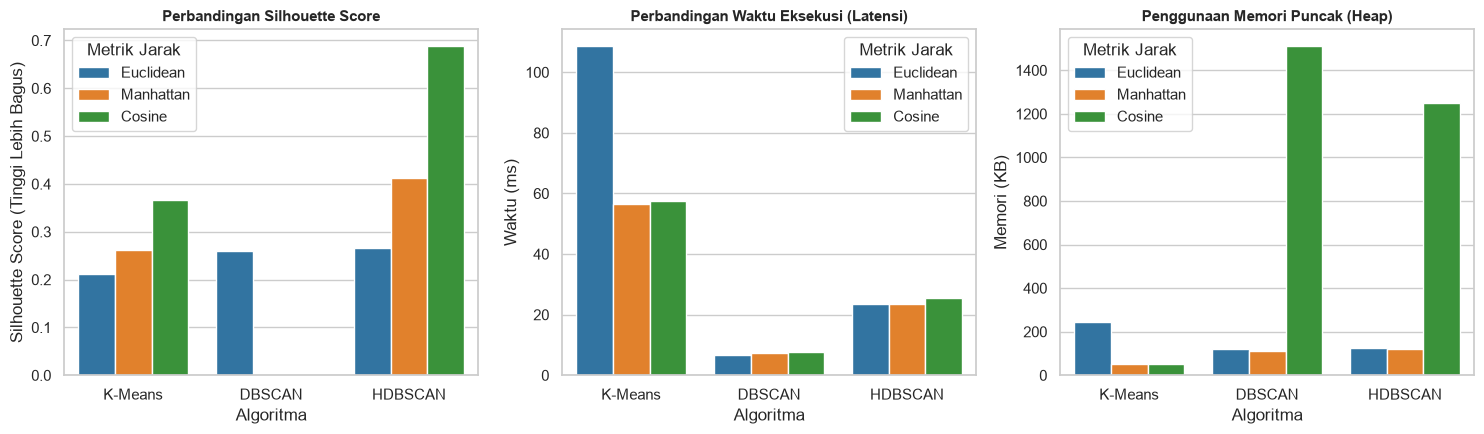

In [4]:
plt.figure(figsize=(15, 4.5))

# Subplot 1: Silhouette Score
plt.subplot(1, 3, 1)
sns.barplot(data=df_benchmark_all, x='Algoritma', y='Silhouette_Score', hue='Metrik', palette='tab10')
plt.title('Perbandingan Silhouette Score', fontsize=11, fontweight='bold')
plt.ylabel('Silhouette Score (Tinggi Lebih Bagus)')
plt.legend(title='Metrik Jarak')

# Subplot 2: Waktu Eksekusi
plt.subplot(1, 3, 2)
sns.barplot(data=df_benchmark_all, x='Algoritma', y='Waktu_Eksekusi (ms)', hue='Metrik', palette='tab10')
plt.title('Perbandingan Waktu Eksekusi (Latensi)', fontsize=11, fontweight='bold')
plt.ylabel('Waktu (ms)')
plt.legend(title='Metrik Jarak')

# Subplot 3: Memori Puncak
plt.subplot(1, 3, 3)
sns.barplot(data=df_benchmark_all, x='Algoritma', y='Memori_Puncak (KB)', hue='Metrik', palette='tab10')
plt.title('Penggunaan Memori Puncak (Heap)', fontsize=11, fontweight='bold')
plt.ylabel('Memori (KB)')
plt.legend(title='Metrik Jarak')

plt.tight_layout()
plt.show()

In [5]:
os.makedirs('../outputs', exist_ok=True)
path_out_bench = '../outputs/benchmark_clustering_uts_js8.csv'
df_benchmark_all.to_csv(path_out_bench, index=False)
print(f"Hasil tolok ukur tersimpan ke: {path_out_bench}")

Hasil tolok ukur tersimpan ke: ../outputs/benchmark_clustering_uts_js8.csv
